In [60]:
from neuron import n
from neuron.units import um, mV, ms

### creating a class to define a cell with 1 soma and 1 dendrite

In [2]:
class BallAndStick():
    def __init__(self,gid):
        self._gid = gid
        self.soma = n.Section("soma", self)
        self.dend = n.Section("dend", self)
    
    def __repr__(self):
        return "BallAndStick[{}]".format(self._gid)

In [3]:
cell1 = BallAndStick(0)
cell2 = BallAndStick(1)

In [5]:
n.topology()


|-|       BallAndStick[0].soma(0-1)
|-|       BallAndStick[0].dend(0-1)
|-|       BallAndStick[1].soma(0-1)
|-|       BallAndStick[1].dend(0-1)



1.0

### connect the sections : connect() method

In [2]:
class BallAndStick():
    def __init__(self,gid):
        self._gid = gid
        self.soma = n.Section("soma", self)
        self.dend = n.Section("dend", self)
        self.dend.connect(self.soma)
    
    def __repr__(self):
        return "BallAndStick[{}]".format(self._gid)

In [16]:
# del cell1, cell2
cell1 = BallAndStick(0)
cell2 = BallAndStick(1)

In [17]:
n.topology() #the output now means that dendrite begins where soma ends


|-|       BallAndStick[0].soma(0-1)
   `|       BallAndStick[0].dend(0-1)
|-|       BallAndStick[1].soma(0-1)
   `|       BallAndStick[1].dend(0-1)



1.0

In [18]:
del cell2

In [19]:
n.topology()


|-|       BallAndStick[0].soma(0-1)
   `|       BallAndStick[0].dend(0-1)



1.0

### what if we did not want to attach dendrite to the end of soma?

define stylized geometry 
- define length and diameter of soma
- define length and diameter of dend

In [2]:
class BallAndStick():
    def __init__(self,gid):
        self._gid = gid
        self.soma = n.Section("soma", self)
        self.dend = n.Section("dend", self)
        self.dend.connect(self.soma)
        self.soma.L = self.soma.diam = 12.6157*um
        self.dend.L = 200*um
        self.dend.diam = 1*um
    
    def __repr__(self):
        return "BallAndStick[{}]".format(self._gid)

In [3]:
cell1 = BallAndStick(0)

In [4]:
n.topology()


|-|       BallAndStick[0].soma(0-1)
   `|       BallAndStick[0].dend(0-1)



1.0

In [7]:
cell1.soma(0.5).area()

500.00296377255506

### How does the cell look now?

<Axis3DWithNEURON: >

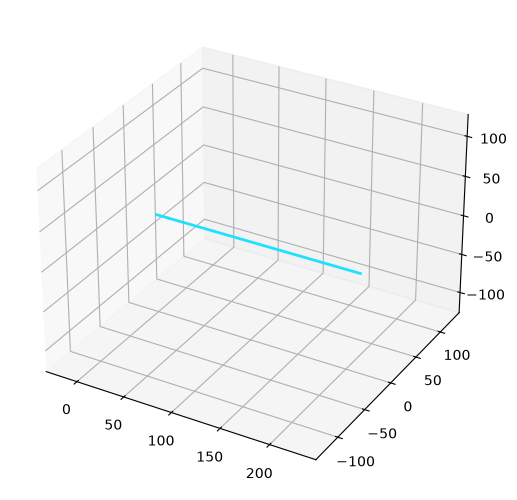

In [16]:
import matplotlib.pyplot as plt
n.PlotShape(False).plot(plt)

In [19]:
#or use neuron's integrated graphics
from neuron import gui
ps = n.PlotShape(True)
ps.show(0) #show the diameter

1

### Specify BioPhysics
- start by setting axial resistance and membrane capacitance

In [8]:
class BallAndStick():
    def __init__(self,gid):
        self._gid = gid
        self.soma = n.Section("soma", self)
        self.dend = n.Section("dend", self)
        self.dend.connect(self.soma)
        self.soma.L = self.soma.diam = 12.6157*um
        self.dend.L = 200*um
        self.dend.diam = 1*um
    
        # self.all = n.SectionList()
        # self.all.append(self.soma)
        # self.all.append(self.dend)
        # above three lines equivalent to below one line
        self.all = self.soma.wholetree()
        for sec in self.all:
            sec.Ra = 100 #Ohm-cm axial resistance
            sec.cm = 1 #mF/cm2 membrane capacitance
    
    def __repr__(self):
        return "BallAndStick[{}]".format(self._gid)

In [9]:
cell1 = BallAndStick(0)

In [10]:
n.topology()


|-|       BallAndStick[0].soma(0-1)
   `|       BallAndStick[0].dend(0-1)



1.0

#### split __init__ into different functions for defining morphology, defining biophysics
- in biophysics, we define the Hodgkin-Hixley kinetics in the soma
- we insert a passive leak current in the dendrite

In [38]:
class BallAndStick():
    def __init__(self, gid):
        self._gid = gid
        self._setup_morphology()
        self._setup_biophysics()
    
    def _setup_morphology(self):
        self.soma = n.Section("soma", self)
        self.dend = n.Section("dend", self)
        self.dend.connect(self.soma)
        self.all = self.soma.wholetree()
        
        self.soma.L = self.soma.diam = 12.6157*um
        self.dend.L = 200*um
        self.dend.diam = 1*um
    
    def _setup_biophysics(self):
        for sec in self.all:
            sec.Ra = 100 #Ohm-cm axial resistance
            sec.cm = 1 #mF/cm2 membrane capacitance
        
        self.soma.insert(n.hh)
        for seg in self.soma:
            seg.hh.gnabar = 0.12 #S/cm2 sodium conductance
            seg.hh.gkbar = 0.036 #S/cm2 potassium conductance
            seg.hh.gl = 0.0003 #S/cm2 leak conductance
            seg.hh.el = -54.3*mV #mV reverse potential
        
        self.dend.insert(n.pas)
        for seg in self.dend:
            seg.pas.g = 0.001 #S/cm2 passive conductance
            seg.pas.e = -65*mV #mV leak reverse potential
    
    def __repr__(self):
        return "BallAndStick[{}]".format(self._gid)



In [39]:
del cell1
cell1 = BallAndStick(0)

In [40]:
n.topology()


|-|       BallAndStick[0].soma(0-1)
   `|       BallAndStick[0].dend(0-1)



1.0

In [41]:
print(n.units("gnabar_hh"))

S/cm2


In [53]:
#use psection to see what is present where
for sec in n.allsec():
    print(sec, sec.psection()["density_mechs"])

BallAndStick[0].soma {'hh': {'gnabar': [0.12], 'gkbar': [0.036], 'gl': [0.0003], 'el': [-54.3], 'gna': [0.0], 'gk': [0.0], 'il': [0.0], 'minf': [0.0], 'hinf': [0.0], 'ninf': [0.0], 'mtau': [0.0], 'htau': [0.0], 'ntau': [0.0], 'm': [0.0], 'h': [0.0], 'n': [0.0]}}
BallAndStick[0].dend {'pas': {'g': [0.001], 'e': [-65.0], 'i': [0.0]}}


### Instrumentation - stimulation (current pulse)
- we inject a current pulse at the distal end (1) of the dendrite

In [49]:
stim = n.IClamp(cell1.dend(1))
stim.get_segment() #to check the segment the current clamp is inserted into

BallAndStick[0].dend(1)

In [50]:
print([item for item in dir(stim) if not item.startswith("__")])

['amp', 'baseattr', 'delay', 'dur', 'get_loc', 'get_segment', 'has_loc', 'hname', 'hocobjptr', 'i', 'loc', 'same']


In [52]:
# setup the current clamp values - delay, duration, and amplitude
stim.delay = 5 #ms
stim.dur = 1 #ms
stim.amp = 0.1 #nA

- recording of membrane potential at the center of soma and the time

In [55]:
soma_v = n.Vector().record(cell1.soma(0.5)._ref_v) #membrane potential vector
t = n.Vector().record(n._ref_t) #time stamp vector

### Run the simulation
- initialize the membrane potential to -65mV everywhere
- run the simulation

In [66]:
n.load_file("stdrun.hoc")

1.0

In [67]:
n.finitialize(-65*mV)

1.0

In [68]:
n.continuerun(25*ms)

0.0

### Plot the results

In [69]:
from bokeh.io import output_notebook
import bokeh.plotting as plt
import numpy as np
output_notebook()

Loading BokehJS ...

In [71]:
f = plt.figure(x_axis_label="t (ms)", y_axis_label="v (mV)", title="membrane potential vs time")
f.line(np.array(t), np.array(soma_v), line_width=2)
plt.show(f)

# More Simulations

### 1. Role of current amplitude
- vary the current amplitude stimulus

In [74]:
f = plt.figure(x_axis_label="t (ms)", y_axis_label="v (mV)", title="membrane potential vs time -- at different current amplitude impulses")
amps = [0.075*i for i in range(1, 5)]
colors = ["green", "blue", "red", "black"]
for amp, color in zip(amps, colors):
    stim.amp = amp
    n.finitialize(-65*mV)
    n.continuerun(25*ms)
    f.line(np.array(t), np.array(soma_v), line_width=2, legend_label="amp=%g" %amp, color=color)

plt.show(f)

- plot both dendrite and soma

In [77]:
dend_v = n.Vector().record(cell1.dend(0.5)._ref_v)
f = plt.figure(x_axis_label="t (ms)", y_axis_label="v (mV)", title="membrane potential vs time -- at different current amplitude impulses in both soma & dendrite")
amps = [0.075*i for i in range(1, 5)]
colors = ["green", "blue", "red", "black"]
for amp, color in zip(amps, colors):
    stim.amp = amp
    n.finitialize(-65*mV)
    n.continuerun(25*ms)
    f.line(np.array(t), np.array(soma_v), line_width=2, legend_label="amp=%g" %amp, color=color)
    f.line(np.array(t), np.array(dend_v), line_width=2, line_dash="dashed", color=color)

plt.show(f)

### 2. constant current impulse

In [87]:
stim.dur = 90 #ms
stim.amp = 0.3 #nA

f = plt.figure(x_axis_label="t (ms)", y_axis_label="v (mV)", title="membrane potential vs time -- at constant current clamp")
n.finitialize(-65*mV)
n.continuerun(100*ms)
f.line(np.array(t), np.array(soma_v), line_width=2)
plt.show(f)

### 3. The role of different `nseg` - number of segments of dendrite

In [97]:
dend_v = n.Vector().record(cell1.dend(0.5)._ref_v)
f = plt.figure(x_axis_label="t (ms)", y_axis_label="v (mV)", title="membrane potential vs time -- for different nseg")
stim.dur = 1*ms
amps = [0.075*i for i in range(1,5)]
colors = ["green", "blue", "red", "black"]
for amp, color in zip(amps, colors):
    stim.amp = amp
    for cell1.dend.nseg, line_width in [(1,2), (101, 1)]:
        n.finitialize(-65*mV)
        n.continuerun(25*ms)
        f.line(np.array(t), np.array(soma_v), line_width=line_width, legend_label="amp=%g" %amp if cell1.dend.nseg==1 else "", color=color)
        f.line(np.array(t), np.array(dend_v), line_width=line_width, line_dash="dashed", color=color)

plt.show(f)